# 8. Strong duality and Slater's condition

## 8.1 When Slater holds [CO 14.4]

### Task
Solve
[
min_{xinmathbb R^2} (x_1-2)^2+(x_2-1)^2
quad	ext{subject to}quad x_1^2+x_2^2le r^2.
]
Plot the feasible disc, objective contours and optimum. Derive and plot the dual function, and compare primal and dual values for (r=0.5,1,3).

### Explore
Exhibit a strictly feasible point. Track (p^*(r)) and (lambda^*(r)), including the radius where the constraint becomes inactive, and compare the multiplier with the sensitivity of (p^*) to the squared-radius budget.

Strict feasibility: x=0 gives ||x||^2-r^2 = -r^2 < 0 for every r>0.


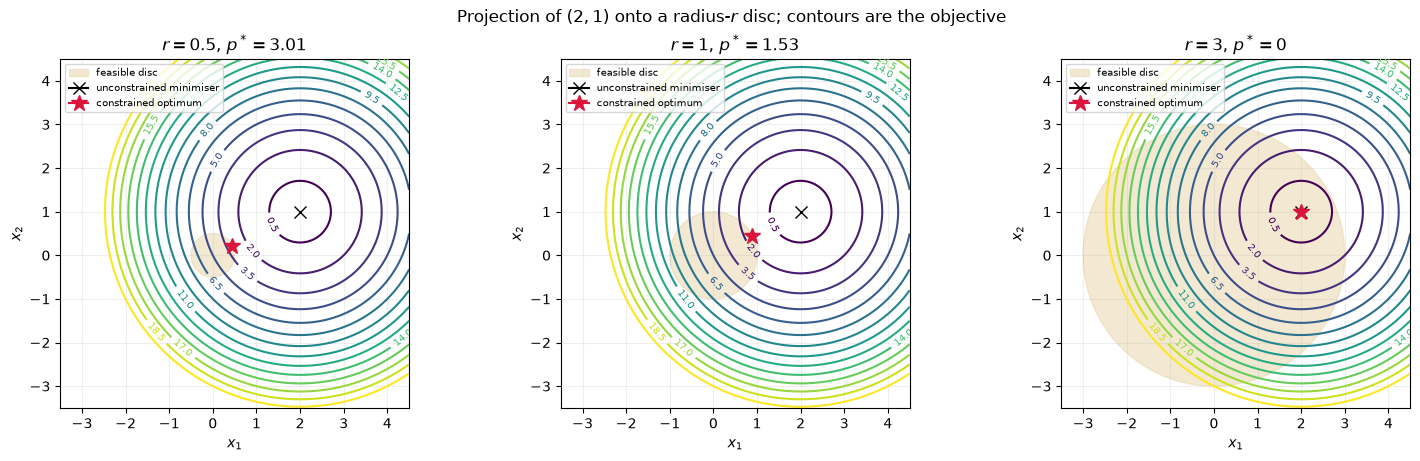

r=0.5: x*=[0.4472136 0.2236068], p*=3.01393202, lambda*=3.47213571, d*=3.01393202
r=1: x*=[0.89442719 0.4472136 ], p*=1.52786405, lambda*=1.23606798, d*=1.52786405
r=3: x*=[2. 1.], p*=0.00000000, lambda*=0.00000000, d*=0.00000000


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

center = np.array([2.0, 1.0])
center_sq = float(center @ center)
center_norm = np.sqrt(center_sq)

def objective_ball(x):
    return float((x - center) @ (x - center))

def dual_ball(lam, r):
    return center_sq * lam / (1.0 + lam) - r**2 * lam

def dual_ball_grad(lam, r):
    return center_sq / (1.0 + lam)**2 - r**2

def ball_solution(r):
    if r >= center_norm:
        return center.copy(), 0.0, 0.0
    lam = center_norm / r - 1.0
    x = center * (r / center_norm)
    p = (center_norm - r)**2
    return x, p, lam

# The Hessians of the objective and squared-norm constraint are both 2I.
assert np.allclose(2.0 * np.eye(2), (2.0 * np.eye(2)).T)
assert np.linalg.eigvalsh(2.0 * np.eye(2)).min() > 0
print("Strict feasibility: x=0 gives ||x||^2-r^2 = -r^2 < 0 for every r>0.")

radii = [0.5, 1.0, 3.0]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
summary = []
for r, ax in zip(radii, axes):
    x_star, p_star, lam_star = ball_solution(r)
    primal = minimize(
        objective_ball,
        x0=np.zeros(2),
        jac=lambda x: 2.0 * (x - center),
        method="SLSQP",
        constraints=[{
            "type": "ineq",
            "fun": lambda x, r=r: r**2 - x @ x,
            "jac": lambda x: -2.0 * x,
        }],
        options={"ftol": 1e-12, "maxiter": 500},
    )
    dual = minimize(
        lambda z, r=r: -dual_ball(z[0], r),
        x0=np.array([0.5]),
        jac=lambda z, r=r: np.array([-dual_ball_grad(z[0], r)]),
        method="SLSQP",
        bounds=[(0.0, None)],
        options={"ftol": 1e-12, "maxiter": 500},
    )
    x_num = primal.x
    lam_num = float(dual.x[0])
    p_num = objective_ball(x_num)
    d_num = dual_ball(lam_num, r)
    stationarity = 2.0 * (x_num - center) + 2.0 * lam_num * x_num
    primal_violation = max(0.0, x_num @ x_num - r**2)
    complementarity = lam_num * (x_num @ x_num - r**2)
    assert primal.success and dual.success
    assert np.allclose(x_num, x_star, atol=2e-6)
    assert np.isclose(p_num, p_star, atol=2e-8)
    assert np.isclose(lam_num, lam_star, atol=2e-5)
    assert lam_num >= -1e-12 and primal_violation <= 1e-9
    assert np.linalg.norm(stationarity) <= 2e-5
    assert abs(complementarity) <= 2e-5
    assert p_num - d_num >= -1e-9
    assert np.isclose(p_num, d_num, atol=2e-7)
    summary.append((r, x_num, p_num, lam_num, d_num))

    grid = np.linspace(-3.5, 4.5, 300)
    X, Y = np.meshgrid(grid, grid)
    Z = (X - center[0])**2 + (Y - center[1])**2
    contours = ax.contour(X, Y, Z, levels=np.arange(0.5, 21, 1.5), cmap="viridis")
    ax.clabel(contours, inline=True, fontsize=7, fmt="%.1f")
    angle = np.linspace(0.0, 2.0 * np.pi, 400)
    ax.fill(r * np.cos(angle), r * np.sin(angle), color="#e6d3a3", alpha=0.48,
            label="feasible disc")
    ax.plot(center[0], center[1], marker="x", color="black", ms=8, label="unconstrained minimiser")
    ax.plot(x_num[0], x_num[1], marker="*", color="crimson", ms=12, label="constrained optimum")
    ax.set(xlabel="$x_1$", ylabel="$x_2$", title=fr"$r={r:g}$, $p^*={p_num:.3g}$")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7, loc="upper left")

plt.suptitle("Projection of $(2,1)$ onto a radius-$r$ disc; contours are the objective")
plt.show()

for r, x_num, p_num, lam_num, d_num in summary:
    print(f"r={r:g}: x*={x_num}, p*={p_num:.8f}, lambda*={lam_num:.8f}, d*={d_num:.8f}")

### Explore: dual function

For (a=(2,1)), completing the square gives (x(lambda)=a/(1+lambda)) and
[
g(lambda)=inf_x L(x,lambda)=
rac{5lambda}{1+lambda}-r^2lambda,qquad lambdage0.
]
Plot this concave function and mark its maximiser alongside the primal value.

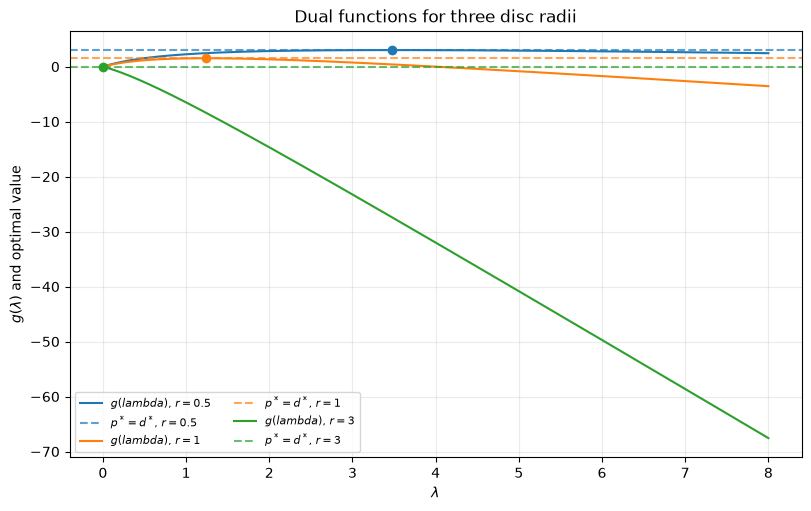

Completed-square dual identity checked at all plotted radii and test multipliers.


In [2]:
lam_grid = np.linspace(0.0, 8.0, 600)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
colors = ["tab:blue", "tab:orange", "tab:green"]
for r, color in zip(radii, colors):
    _, p_star, lam_star = ball_solution(r)
    g_values = dual_ball(lam_grid, r)
    ax.plot(lam_grid, g_values, color=color, label=fr"$g(lambda)$, $r={r:g}$")
    ax.axhline(p_star, color=color, linestyle="--", alpha=0.7,
               label=fr"$p^*=d^*$, $r={r:g}$")
    ax.plot(lam_star, dual_ball(lam_star, r), marker="o", color=color)
    assert np.isclose(dual_ball_grad(lam_star, r), 0.0, atol=1e-12) if lam_star > 0 else dual_ball_grad(0.0, r) <= 0
ax.set(xlabel=r"$\lambda$", ylabel=r"$g(\lambda)$ and optimal value",
       title="Dual functions for three disc radii")
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=8)
plt.show()

# Check the closed-form dual identity at representative x and lambda values.
for r in radii:
    for lam in [0.0, 0.5, 2.0]:
        x_min = center / (1.0 + lam)
        lagrangian = objective_ball(x_min) + lam * (x_min @ x_min - r**2)
        assert np.isclose(lagrangian, dual_ball(lam, r), atol=1e-12)
print("Completed-square dual identity checked at all plotted radii and test multipliers.")

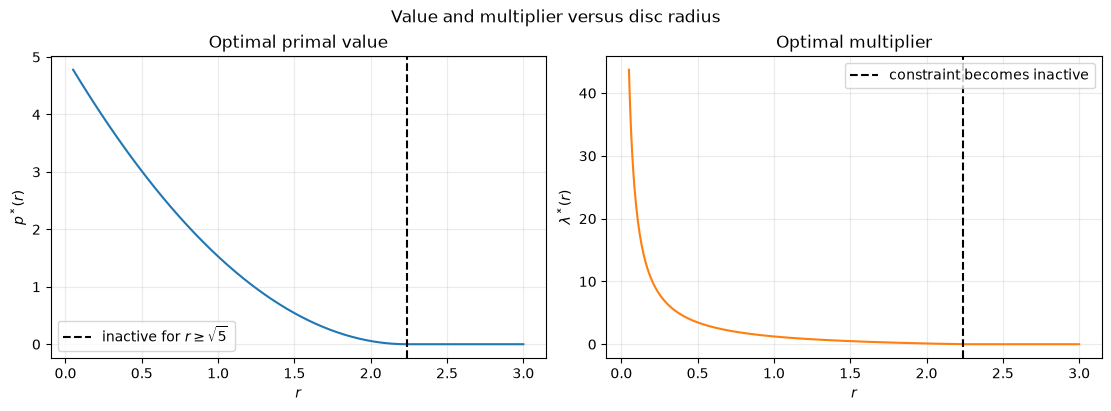

s=r^2=0.25: finite-difference dp*/ds=-3.47213596, -lambda*=-3.47213595
s=r^2=1: finite-difference dp*/ds=-1.23606798, -lambda*=-1.23606798
s=r^2=4: finite-difference dp*/ds=-0.11803399, -lambda*=-0.11803399
s=r^2=6: finite-difference dp*/ds=0.00000000, -lambda*=-0.00000000
s=r^2=9: finite-difference dp*/ds=0.00000000, -lambda*=-0.00000000
As r approaches zero, lambda* grows without bound; at r=0 the dual supremum is not attained.


In [3]:
def p_of_squared_radius(s):
    return (center_norm - np.sqrt(s))**2 if s < center_sq else 0.0

def lambda_of_squared_radius(s):
    return max(center_norm / np.sqrt(s) - 1.0, 0.0)

r_grid = np.linspace(0.05, 3.0, 500)
p_grid = np.array([p_of_squared_radius(r**2) for r in r_grid])
lam_star_grid = np.array([lambda_of_squared_radius(r**2) for r in r_grid])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(r_grid, p_grid, color="tab:blue")
axes[0].axvline(center_norm, color="black", linestyle="--", label=fr"inactive for $r\geq\sqrt{{5}}$")
axes[0].set(xlabel="$r$", ylabel="$p^*(r)$", title="Optimal primal value")
axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].plot(r_grid, lam_star_grid, color="tab:orange")
axes[1].axvline(center_norm, color="black", linestyle="--", label="constraint becomes inactive")
axes[1].set(xlabel="$r$", ylabel=r"$\lambda^*(r)$", title="Optimal multiplier")
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.suptitle("Value and multiplier versus disc radius")
plt.show()

# Envelope sensitivity: with s=r^2, dp*/ds = -lambda* away from the endpoint.
for s in [0.25, 1.0, 4.0, 6.0, 9.0]:
    h = 1e-5
    derivative_fd = (p_of_squared_radius(s + h) - p_of_squared_radius(s - h)) / (2.0 * h)
    expected = -lambda_of_squared_radius(s)
    assert np.isclose(derivative_fd, expected, rtol=1e-7, atol=5e-9)
    print(f"s=r^2={s:g}: finite-difference dp*/ds={derivative_fd:.8f}, -lambda*={expected:.8f}")
print("As r approaches zero, lambda* grows without bound; at r=0 the dual supremum is not attained.")

### Explain

The origin is strictly feasible whenever (r>0). Once the unconstrained minimiser lies inside the disc, the constraint is inactive and its multiplier is zero. For squared-radius budget (s=r^2), the value sensitivity is (dp^*/ds=-lambda^*): the multiplier measures the marginal value of enlarging the disc. At (r=0), Slater fails and the dual supremum is not attained.

## 8.2 When Slater fails [CO 14.4]

### Task (a): a zero-radius constraint

Study (min_x -x) subject to (x^2le0). The statement's requested formula (g(lambda)=-1/(4lambda)) implies the objective (-x). Compute and plot the dual function and its supremum.

### Task (b): the classical gap example

Study (min_{xinmathbb R, y>0} e^{-x}) subject to (x^2/yle0). Plot the feasible set and show numerically along ((x,y)=(t,t^3)), as (t	oinfty), that (g(lambda)=0) for every (lambdage0).

lambda=0.25: scipy x_min=2.00000000, g=-1.00000000; closed form checked
lambda=1: scipy x_min=0.50000000, g=-0.25000000; closed form checked
lambda=4: scipy x_min=0.12500000, g=-0.06250000; closed form checked
lambda sequence: [1.e+00 1.e+01 1.e+02 1.e+03 1.e+05]
dual values approach the unattained supremum 0: [-2.5e-01 -2.5e-02 -2.5e-03 -2.5e-04 -2.5e-06]


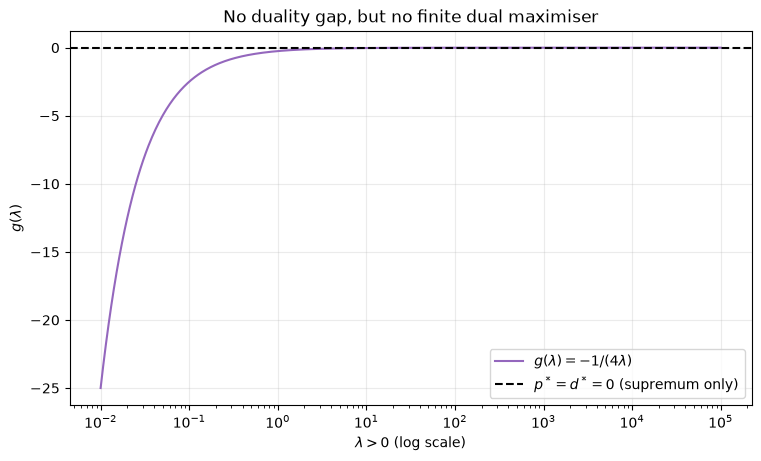

In [4]:
from scipy.optimize import minimize

# (a) Feasibility forces x=0, so p*=0. For lambda>0, minimizing
# lambda*x^2-x gives x(lambda)=1/(2 lambda), g(lambda)=-1/(4 lambda).
primal_a = minimize(
    lambda z: -z[0],
    x0=np.array([0.7]),
    jac=lambda z: np.array([-1.0]),
    method="SLSQP",
    constraints=[{"type": "eq", "fun": lambda z: z[0], "jac": lambda z: np.array([1.0])}],
    options={"ftol": 1e-12, "maxiter": 200},
)
assert primal_a.success
x_a = float(primal_a.x[0])
p_a = -x_a
assert abs(x_a) <= 1e-10 and np.isclose(p_a, 0.0, atol=1e-10)

for lam in [0.25, 1.0, 4.0]:
    inner = minimize(
        lambda z, lam=lam: lam * z[0]**2 - z[0],
        x0=np.array([0.0]),
        jac=lambda z, lam=lam: np.array([2.0 * lam * z[0] - 1.0]),
        method="BFGS",
        options={"gtol": 1e-12},
    )
    x_exact = 1.0 / (2.0 * lam)
    g_exact = -1.0 / (4.0 * lam)
    assert inner.success
    assert np.isclose(inner.x[0], x_exact, atol=1e-8)
    assert np.isclose(inner.fun, g_exact, atol=1e-10)
    assert lam >= 0
    print(f"lambda={lam:g}: scipy x_min={inner.x[0]:.8f}, g={inner.fun:.8f}; closed form checked")

# At lambda=0 the inner infimum is -infinity. For positive lambda, g increases
# toward zero as lambda grows, so d*=0 but there is no finite dual maximiser.
lam_sequence = np.array([1.0, 10.0, 100.0, 1e3, 1e5])
g_sequence = -1.0 / (4.0 * lam_sequence)
assert np.all(np.diff(g_sequence) > 0) and np.all(g_sequence < 0)
assert np.isclose(p_a - 0.0, 0.0)  # zero primal-dual gap; dual value is a supremum
print("lambda sequence:", lam_sequence)
print("dual values approach the unattained supremum 0:", g_sequence)

lam_plot = np.logspace(-2, 5, 700)
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
ax.semilogx(lam_plot, -1.0 / (4.0 * lam_plot), color="tab:purple", label=r"$g(\lambda)=-1/(4\lambda)$")
ax.axhline(0.0, color="black", linestyle="--", label="$p^*=d^*=0$ (supremum only)")
ax.set(xlabel=r"$\lambda>0$ (log scale)", ylabel=r"$g(\lambda)$",
       title="No duality gap, but no finite dual maximiser")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

Reduced-coordinate SLSQP: x=0, y=1, p=1.00000000, x^2/y=0
lambda=0: L(t=20)=2.06115e-09, L(t=10000)=0, lower bound 0
lambda=0.5: L(t=20)=0.025, L(t=10000)=5e-05, lower bound 0
lambda=2: L(t=20)=0.1, L(t=10000)=0.0002, lower bound 0
lambda=5: L(t=20)=0.25, L(t=10000)=0.0005, lower bound 0


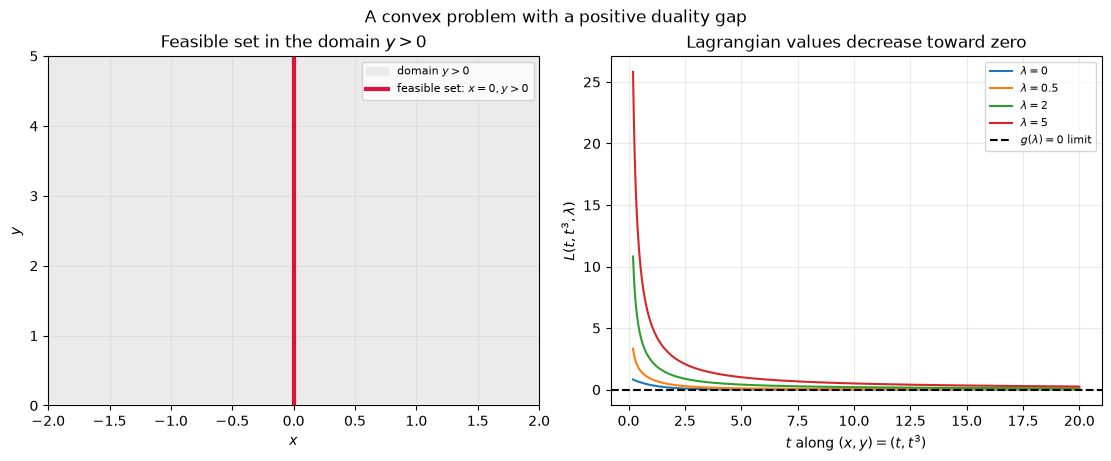

For every lambda>=0, g(lambda)=0; d*=0.0, p*=1.0, gap=1.0.


In [5]:
# (b) The feasible set is exactly x=0, y>0, so p*=exp(0)=1.
# Use z=log(y) to keep y positive in the numerical primal solve.
primal_b = minimize(
    lambda z: np.exp(-z[0]),
    x0=np.array([0.4, 0.0]),
    jac=lambda z: np.array([-np.exp(-z[0]), 0.0]),
    method="SLSQP",
    constraints=[{"type": "eq", "fun": lambda z: z[0], "jac": lambda z: np.array([1.0, 0.0])}],
    options={"ftol": 1e-12, "maxiter": 200},
)
assert primal_b.success
x_b, log_y_b = primal_b.x
y_b = float(np.exp(log_y_b))
p_b = float(np.exp(-x_b))
constraint_b = x_b**2 / y_b
assert y_b > 0 and abs(x_b) <= 1e-10 and abs(constraint_b) <= 1e-12
assert np.isclose(p_b, 1.0, atol=1e-10)
print(f"Reduced-coordinate SLSQP: x={x_b:.3g}, y={y_b:.6g}, p={p_b:.8f}, x^2/y={constraint_b:.3g}")

# Verify convexity of the perspective constraint numerically: its Hessian is PSD
# for y>0 (the objective exp(-x) also has positive second derivative).
for x_test in [-2.0, -0.5, 0.0, 0.7, 3.0]:
    for y_test in [0.2, 1.0, 4.0]:
        hessian = np.array([
            [2.0 / y_test, -2.0 * x_test / y_test**2],
            [-2.0 * x_test / y_test**2, 2.0 * x_test**2 / y_test**3],
        ])
        assert np.linalg.eigvalsh(hessian).min() >= -1e-12
        assert np.exp(-x_test) > 0

# L=e^-t + lambda/t along x=t, y=t^3. It is nonnegative and tends to zero,
# proving the inner infimum is zero for every fixed lambda>=0.
t = np.linspace(0.2, 20.0, 600)
lambdas_b = [0.0, 0.5, 2.0, 5.0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ax = axes[0]
y_domain = np.linspace(0.03, 5.0, 200)
ax.fill_betweenx(y_domain, -2.0, 2.0, color="0.92", label="domain $y>0$")
ax.plot(np.zeros_like(y_domain), y_domain, color="crimson", linewidth=3,
        label="feasible set: $x=0, y>0$")
ax.set(xlim=(-2.0, 2.0), ylim=(0.0, 5.0), xlabel="$x$", ylabel="$y$",
       title="Feasible set in the domain $y>0$")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)

ax = axes[1]
for lam in lambdas_b:
    values = np.exp(-t) + lam / t
    assert np.all(values >= 0.0)
    assert np.all(np.diff(values) <= 1e-14)
    assert values[-1] < values[0]
    ax.plot(t, values, label=fr"$\lambda={lam:g}$")
    # Explicit tail values are numerical upper bounds converging to g(lambda)=0.
    tail = np.exp(-1e4) + lam / 1e4
    assert tail >= 0.0 and tail < values[0]
    print(f"lambda={lam:g}: L(t=20)={values[-1]:.6g}, L(t=10000)={tail:.6g}, lower bound 0")
ax.axhline(0.0, color="black", linestyle="--", label=r"$g(\lambda)=0$ limit")
ax.set(xlabel="$t$ along $(x,y)=(t,t^3)$", ylabel=r"$L(t,t^3,\lambda)$",
       title="Lagrangian values decrease toward zero")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
plt.suptitle("A convex problem with a positive duality gap")
plt.show()

p_dual_b = 0.0
assert p_b - p_dual_b >= 0.0
assert np.isclose(p_b - p_dual_b, 1.0, atol=1e-12)
print(f"For every lambda>=0, g(lambda)=0; d*={p_dual_b:.1f}, p*={p_b:.1f}, gap={p_b-p_dual_b:.1f}.")

### Explain

In (a), the feasible set has no strictly feasible point: the inequality is tight everywhere feasible. Strong duality still holds, but the dual supremum is not attained. In (b), feasibility likewise forces equality, and the primal value is strictly above the dual value. Both problems are convex, so convexity alone guarantees neither strong duality nor dual attainment; Slater's condition supplies the needed qualification.